IMPORTING LIBRARIES

In [23]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")

LOADING THE DATASET


In [24]:
url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


SHOWING NO. OF ROWS AND COLUMNS

In [25]:
print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (768, 9)
Number of Rows: 768
Number of Columns: 9


DISPLAYING COLUMNS NAMES

In [26]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


DISPLAY FIRST 5 RECORDS

In [27]:
display(df.head())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


LAST 5 RECORDS

In [28]:
display(df.tail())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


CHECKING DATASET INFORMATION

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


SHOWCASING STATISTICAL SUMMARY

In [30]:
display(df.describe())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


CHECKING MISSING VALUES

In [31]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


CHECKING DUPLICATE RECORDS

In [32]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


COUNTING DIABETES OUTCOMES

In [33]:
print(df["Outcome"].value_counts())

Outcome
0    500
1    268
Name: count, dtype: int64


VISUALIZING OUTCOME DISTRIBUTION

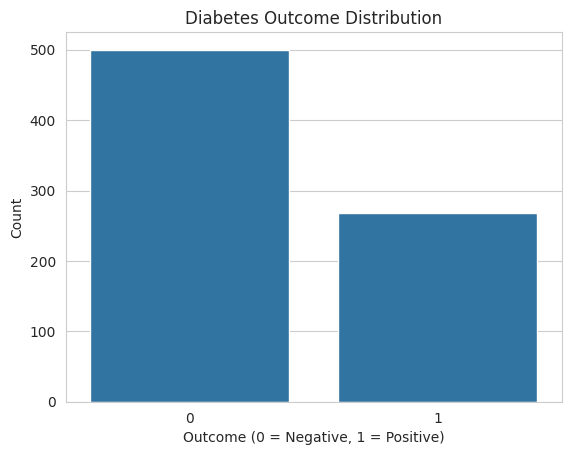

In [34]:
sns.countplot(x="Outcome", data=df)
plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = Negative, 1 = Positive)")
plt.ylabel("Count")
plt.show()

CHECK ZERO VALUES IN MEDICAL MEASUREMENTS

In [35]:
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

print("Zero Values:")
print((df[cols] == 0).sum())

Zero Values:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


CREATING THE CLEANED COPY

In [36]:
df_clean = df.copy()

df_clean[cols] = df_clean[cols].replace(0, np.nan)

print("Missing values after replacing zeros:")
print(df_clean[cols].isnull().sum())

Missing values after replacing zeros:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


FILLING THE MISSED VALUES USING MEDIAN

In [37]:
df_clean[cols] = df_clean[cols].fillna(df_clean[cols].median())

print("Missing values after cleaning:")
print(df_clean.isnull().sum())

Missing values after cleaning:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


PLOT GLUCOSE DISTRIBUTION

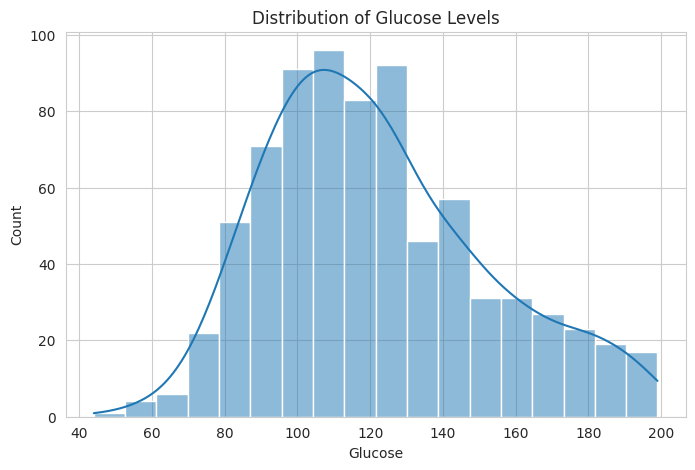

In [38]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean, x="Glucose", kde=True)
plt.title("Distribution of Glucose Levels")
plt.xlabel("Glucose")
plt.show()

PLOT DISTRIBUTION OF ALL FEATURES

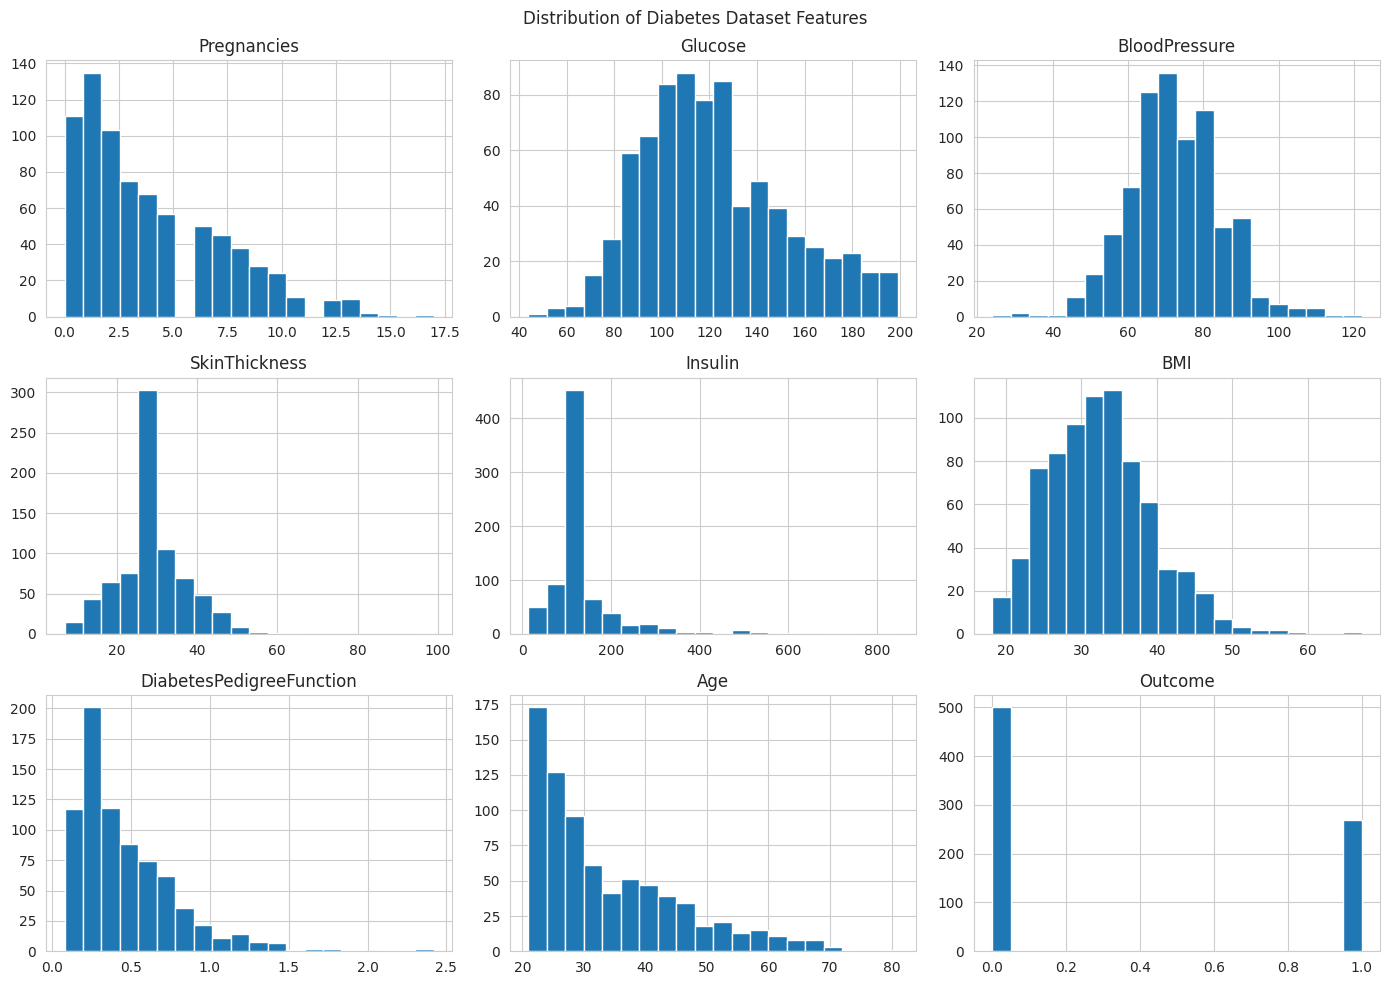

In [39]:
df_clean.hist(figsize=(14, 10), bins=20)
plt.suptitle("Distribution of Diabetes Dataset Features")
plt.tight_layout()
plt.show()

CORRELATION HEATMAP

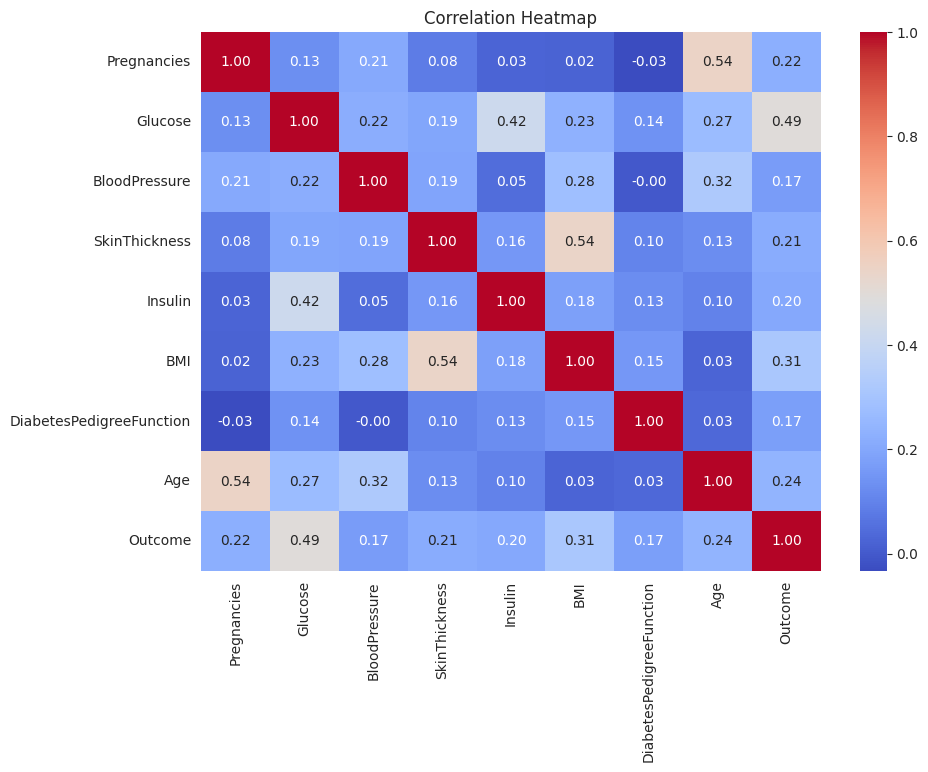

In [40]:
plt.figure(figsize=(10, 7))
sns.heatmap(df_clean.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

COMPARE GLUCOSE BY OUTCOMES

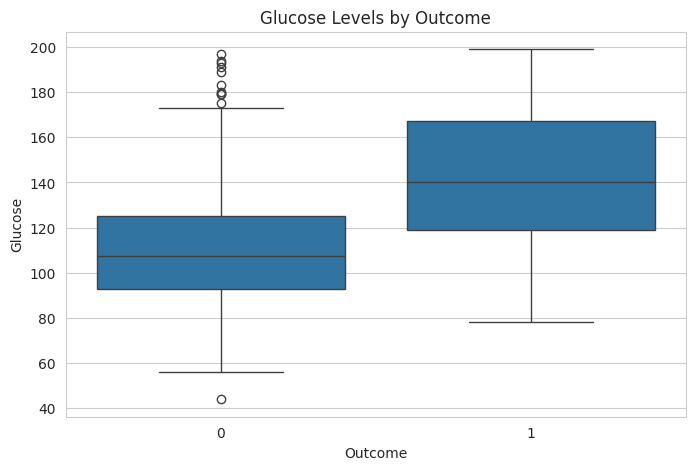

In [41]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="Outcome", y="Glucose")
plt.title("Glucose Levels by Outcome")
plt.show()

COMPARE BMI BY OUTCOMES

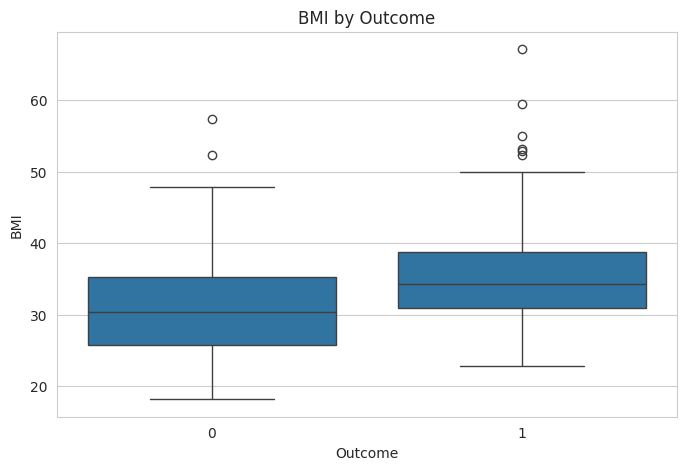

In [42]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="Outcome", y="BMI")
plt.title("BMI by Outcome")
plt.show()

COMPARE AGE BY OUTCOMES


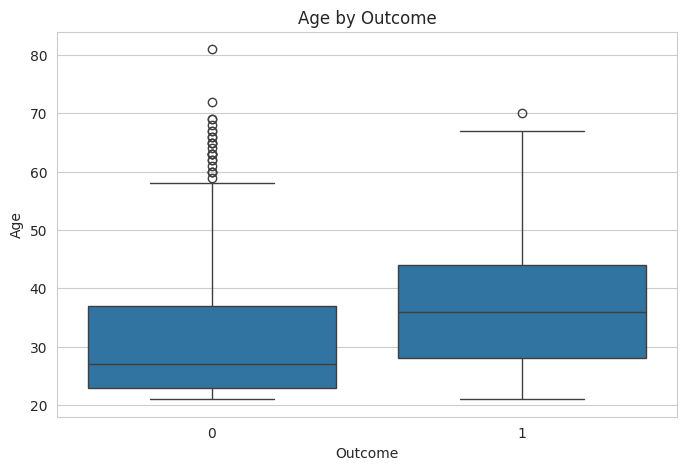

In [43]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="Outcome", y="Age")
plt.title("Age by Outcome")
plt.show()

COMPARE AVERAGE OUTCOMES BY OUTCOMES

In [44]:
display(df_clean.groupby("Outcome").mean().round(2))

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Outcome,,,,,,,,
0,3.30,110.68,70.92,27.73,127.79,30.89,0.43,31.19
1,4.87,142.13,75.12,31.69,164.70,35.38,0.55,37.07


FIND CORRELATION WITH THE OUTCOME

In [45]:
correlation = df_clean.corr()["Outcome"].drop("Outcome")

display(
    correlation.sort_values(ascending=False).to_frame("Correlation")
)

,Correlation
Glucose,0.492782
BMI,0.312038
Age,0.238356
Pregnancies,0.221898
SkinThickness,0.214873
Insulin,0.203790
DiabetesPedigreeFunction,0.173844
BloodPressure,0.165723


FINAL DATASET

In [46]:
print("Final Dataset Shape:", df_clean.shape)
print("Total Missing Values:", df_clean.isnull().sum().sum())
print("Duplicate Rows:", df_clean.duplicated().sum())

print("\nOutcome Counts:")
print(df_clean["Outcome"].value_counts())

Final Dataset Shape: (768, 9)
Total Missing Values: 0
Duplicate Rows: 0

Outcome Counts:
Outcome
0    500
1    268
Name: count, dtype: int64


Exploratory Data Analysis was performed on the diabetes dataset to understand its structure, statistical properties, distributions, and relationships between features. Missing values and duplicate records were examined, and selected zero measurements were treated as unavailable values and filled using median imputation. Histograms, box plots, and a correlation heatmap were used to explore the data. The analysis helps identify patterns in the dataset but does not establish causation or provide a medical diagnosis.